# Imputed consumer fraud probabilities: how they behave

A visual check on the imputation tested in Part C of `fraud_penalty.ipynb`. §7–8 then apply it with a cutoff of 50 and show how the top 100 changes, and §9 plots the raw scores to check that the early window is under-scored. No files are written, and the adopted ranking is left as it is.

**Background.** Consumer fraud scores exist only for 28 Feb 2021 – 27 Feb 2022, and transactions run to 26 Oct 2022. The imputation gives each user-day a fraud probability from how much that user spent that day: for each band of daily spend it takes the spend-weighted average probability over all user-days in the band, counting unscored days as 0. The lookup is fitted on 28 Aug 2021 – 27 Feb 2022, the part of the window where every large day carries a score.

**In every figure:** blue is the supplied (real) scores, red is the imputation.

| Period | Dates | What we have |
|---|---|---|
| Early window | 28 Feb – 27 Aug 2021 | real scores, partial coverage |
| Late window | 28 Aug 2021 – 27 Feb 2022 | real scores, full coverage (the lookup is fitted here) |
| After the window | 28 Feb – 26 Oct 2022 | no scores; imputed only |

## 1. Setup

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from pyspark.sql import SparkSession, functions as F
from scipy.stats import spearmanr

# Works when launched from the repository, project2, or notebooks directory.
PROJECT_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                     if p.name == "project2"), None)
if PROJECT_ROOT is None:
    PROJECT_ROOT = Path.cwd() / "project2"
PROCESSED_PATH = PROJECT_ROOT / "data" / "tables" / "processed"
if not PROCESSED_PATH.is_dir():
    raise FileNotFoundError("Set PROJECT_ROOT to your project2 directory.")
spark = SparkSession.builder.config("spark.driver.memory", "6g").getOrCreate()

START, END = "2021-02-28", "2022-02-27"     # consumer fraud scores exist only in this window
REGIME_START = "2021-08-28"                 # scoring coverage is complete from here
# Lowest score that counts: every score / 30 and above (adopted in fraud_penalty) / 50 and above (§7-8)
MIN_SCORES = [0, 30, 50]
BINS_PER_DECADE = 10                        # log-spaced bands of a user's total spend that day
MAX_SPEND_BIN = int(np.floor(np.log10(20_000) * BINS_PER_DECADE))   # pool everything above about $20K

OBS_BLUE, IMP_RED = "#4C78A8", "#d62728"
sns.set_style("whitegrid", {"grid.color": "#ececec"})


def shade_periods(ax, label=True):
    """Shade the three periods: real scores (two blues) and imputed only (red)."""
    spans = [(START, REGIME_START, OBS_BLUE, 0.07, "real scores, partial coverage"),
             (REGIME_START, "2022-02-28", OBS_BLUE, 0.17, "real scores, full coverage"),
             ("2022-02-28", "2022-10-27", IMP_RED, 0.08, "no scores: imputed only")]
    for a, b, colour, alpha, name in spans:
        ax.axvspan(pd.Timestamp(a), pd.Timestamp(b), color=colour, alpha=alpha, linewidth=0,
                   label=name if label else None)
    ax.set_xlim(pd.Timestamp(START), pd.Timestamp("2022-10-27"))
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/10/08 13:52:52 WARN Utils: Your hostname, Matthews-MacBook-Air.local, resolves to a loopback address: 127.0.0.1; using 10.12.89.139 instead (on interface en0)
26/10/08 13:52:52 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


/Users/matthewlinfred/MAST30034_Python/project2/.proj2_bnpl/lib/python3.12/site-packages/pyspark/testing/utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
26/10/08 13:52:53 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


26/10/08 13:52:53 WARN Utils: Service 'SparkUI' could not bind on port 4040. Attempting port 4041.
26/10/08 13:52:53 WARN Utils: Service 'SparkUI' could not bind on port 4041. Attempting port 4042.
26/10/08 13:52:53 WARN Utils: Service 'SparkUI' could not bind on port 4042. Attempting port 4043.
26/10/08 13:52:53 WARN Utils: Service 'SparkUI' could not bind on port 4043. Attempting port 4044.


## 2. User-days and the spend-band lookup

One row per user per day, with that day's total spend and the supplied score where there is one.

In [2]:
def p_if_at_least(score_col, min_score):
    return F.when(F.col(score_col) >= min_score, F.col(score_col) / 100).otherwise(0.0)


consumer_scores = (spark.read.parquet(str(PROCESSED_PATH / "consumer_fraud_probability"))
                   .where(F.col("fraud_probability").isNotNull())
                   .select("user_id", F.to_date("order_datetime").alias("order_date"),
                           F.col("fraud_probability").alias("consumer_score")))
user_days = (
    spark.read.parquet(str(PROCESSED_PATH / "transactions_clean"))
    .withColumn("order_date", F.to_date("order_datetime"))
    .groupBy("user_id", "order_date").agg(F.sum("dollar_value").alias("day_spend"))
    .join(consumer_scores, ["user_id", "order_date"], "left")
    .withColumn("spend_bin", F.least(F.floor(F.log10("day_spend") * BINS_PER_DECADE), F.lit(MAX_SPEND_BIN)))
).cache()


def build_lookup(days):
    """Spend-weighted fraud probability per spend band, over scored and unscored user-days alike."""
    return days.groupBy("spend_bin").agg(
        F.count("*").alias("days"),
        F.avg(F.col("consumer_score").isNotNull().cast("double")).alias("share_scored"),
        F.min("day_spend").alias("spend_from"),
        *[(F.sum(p_if_at_least("consumer_score", m) * F.col("day_spend")) / F.sum("day_spend")).alias(f"p_day_min{m}")
          for m in MIN_SCORES])


late_days = user_days.where(F.col("order_date").between(REGIME_START, END))
early_days = user_days.where((F.col("order_date") >= START) & (F.col("order_date") < REGIME_START))
lookup = build_lookup(late_days).cache()                    # the one used for the imputation
lookup_late = lookup.toPandas().sort_values("spend_bin")
lookup_early = build_lookup(early_days).toPandas().sort_values("spend_bin")   # for comparison only
print(f"{user_days.count():,} user-days; lookup has {len(lookup_late)} spend bands")

/Users/matthewlinfred/MAST30034_Python/project2/.proj2_bnpl/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


/Users/matthewlinfred/MAST30034_Python/project2/.proj2_bnpl/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


8,976,957 user-days; lookup has 81 spend bands


## 3. What the lookup looks like

The imputation is this curve. Both regimes are drawn so the difference between them is visible; only the later one is used.

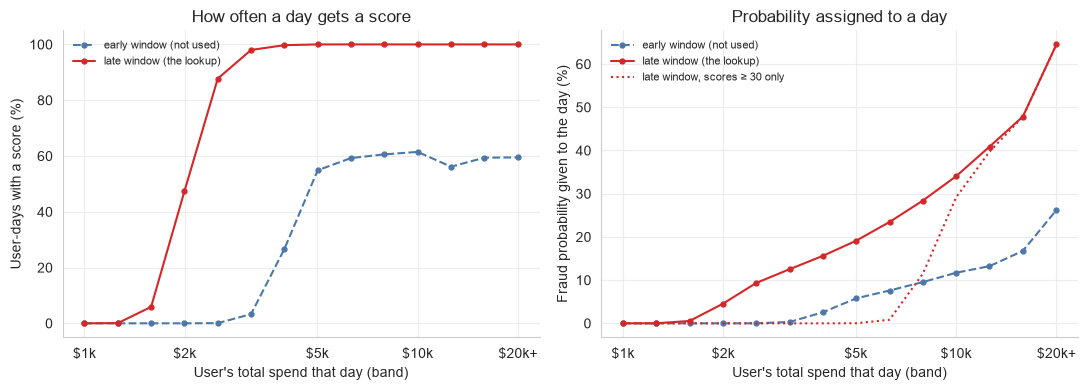

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for frame, colour, style, name in [(lookup_early, OBS_BLUE, "--", "early window (not used)"),
                                   (lookup_late, IMP_RED, "-", "late window (the lookup)")]:
    part = frame[frame["spend_from"] >= 800]
    axes[0].plot(part["spend_from"], part["share_scored"] * 100, color=colour, linestyle=style,
                 marker="o", markersize=3.5, linewidth=1.5, label=name)
    axes[1].plot(part["spend_from"], part["p_day_min0"] * 100, color=colour, linestyle=style,
                 marker="o", markersize=3.5, linewidth=1.5, label=name)
axes[1].plot(lookup_late.loc[lookup_late["spend_from"] >= 800, "spend_from"],
             lookup_late.loc[lookup_late["spend_from"] >= 800, "p_day_min30"] * 100,
             color=IMP_RED, linestyle=":", linewidth=1.5, label="late window, scores ≥ 30 only")
for ax, title, ylabel in [(axes[0], "How often a day gets a score", "User-days with a score (%)"),
                          (axes[1], "Probability assigned to a day", "Fraud probability given to the day (%)")]:
    ax.set_xscale("log")
    ax.set_xticks([1000, 2000, 5000, 10000, 20000], ["$1k", "$2k", "$5k", "$10k", "$20k+"])
    ax.minorticks_off()
    ax.set(xlabel="User's total spend that day (band)", ylabel=ylabel, title=title)
    ax.legend(frameon=False, fontsize=8)
    sns.despine(ax=ax)
fig.tight_layout()
plt.show()

## 4. Through time: real scores against the imputation

Expected fraud loss per \$100 transacted, as a 7-day rolling figure. The imputed line is drawn across the **whole** dataset, including the months that have real scores, so the two can be compared directly where both exist.

<>:27: SyntaxWarning: invalid escape sequence '\$'
<>:27: SyntaxWarning: invalid escape sequence '\$'
/var/folders/kv/bykr7sfs0439lgz122sd6d580000gn/T/ipykernel_46237/52923080.py:27: SyntaxWarning: invalid escape sequence '\$'
  ax.set(ylabel="Expected loss per \$100 transacted (dollars)", title=title)
/Users/matthewlinfred/MAST30034_Python/project2/.proj2_bnpl/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


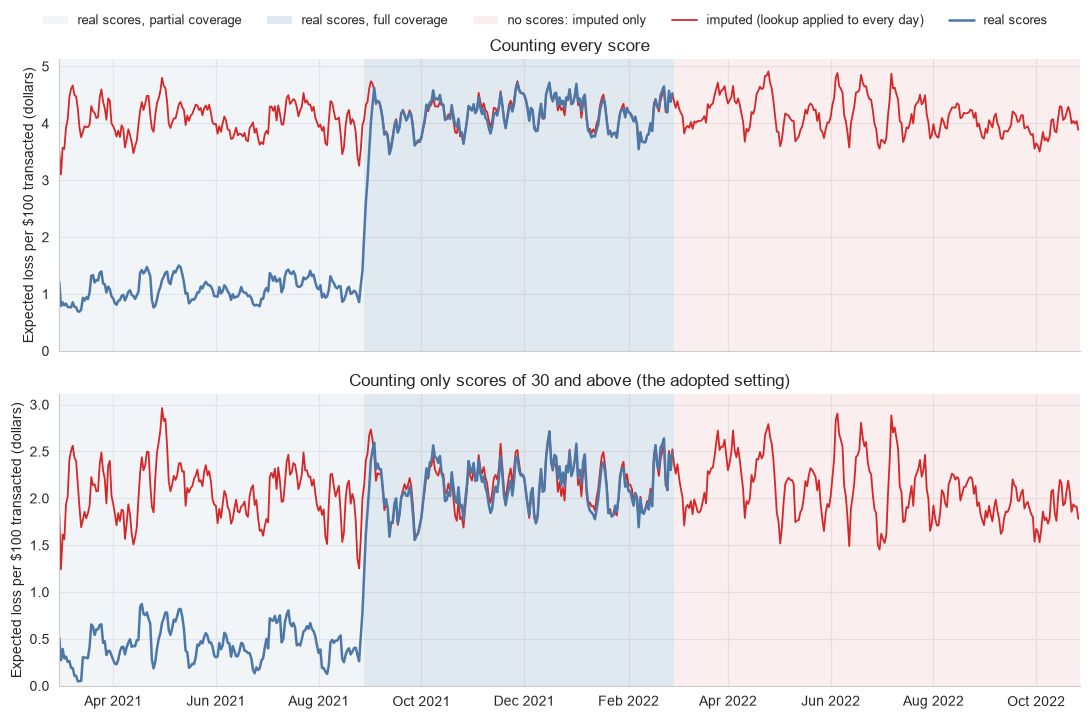

In [4]:
daily = (
    user_days.join(F.broadcast(lookup.select("spend_bin", "share_scored", *[f"p_day_min{m}" for m in MIN_SCORES])),
                   "spend_bin", "left")
    .groupBy("order_date")
    .agg(F.sum("day_spend").alias("value"),
         F.sum(F.col("consumer_score").isNotNull().cast("int")).alias("scored_days"),
         F.sum(F.coalesce("share_scored", F.lit(0.0))).alias("expected_scored_days"),
         *[F.sum(p_if_at_least("consumer_score", m) * F.col("day_spend")).alias(f"observed_loss_min{m}")
           for m in MIN_SCORES],
         *[F.sum(F.coalesce(F.col(f"p_day_min{m}"), F.lit(0.0)) * F.col("day_spend")).alias(f"imputed_loss_min{m}")
           for m in MIN_SCORES])
    .toPandas()
)
daily["order_date"] = pd.to_datetime(daily["order_date"])
daily = daily.sort_values("order_date").set_index("order_date")
in_window = (daily.index >= START) & (daily.index <= END)

rolling = daily.rolling("7D").sum()
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
for ax, m, title in [(axes[0], 0, "Counting every score"),
                     (axes[1], 30, "Counting only scores of 30 and above (the adopted setting)")]:
    observed = (rolling[f"observed_loss_min{m}"] / rolling["value"] * 100).where(in_window)
    imputed = rolling[f"imputed_loss_min{m}"] / rolling["value"] * 100
    shade_periods(ax, label=(m == 0))
    ax.plot(imputed.index, imputed, color=IMP_RED, linewidth=1.3, label="imputed (lookup applied to every day)")
    ax.plot(observed.index, observed, color=OBS_BLUE, linewidth=1.8, label="real scores")
    ax.set(ylabel="Expected loss per \$100 transacted (dollars)", title=title)
    ax.set_ylim(0, None)
    sns.despine(ax=ax)
fig.legend(*axes[0].get_legend_handles_labels(), frameon=False, fontsize=9, ncol=5,
           loc="upper center", bbox_to_anchor=(0.5, 1.03))
fig.tight_layout()
plt.show()

## 5. What the imputation adds, month by month

Expected loss in dollars. Blue is what the real scores give. Solid red is the imputed loss after the window (Test A in `fraud_penalty.ipynb`). Hatched red is the extra loss if the under-scored early months are re-priced from the lookup as well (Test B).

MIN_SCORE  0: real $38.3M | imputed after the window $41.2M | early top-up $18.0M
MIN_SCORE 30: real $19.0M | imputed after the window $20.8M | early top-up $9.7M


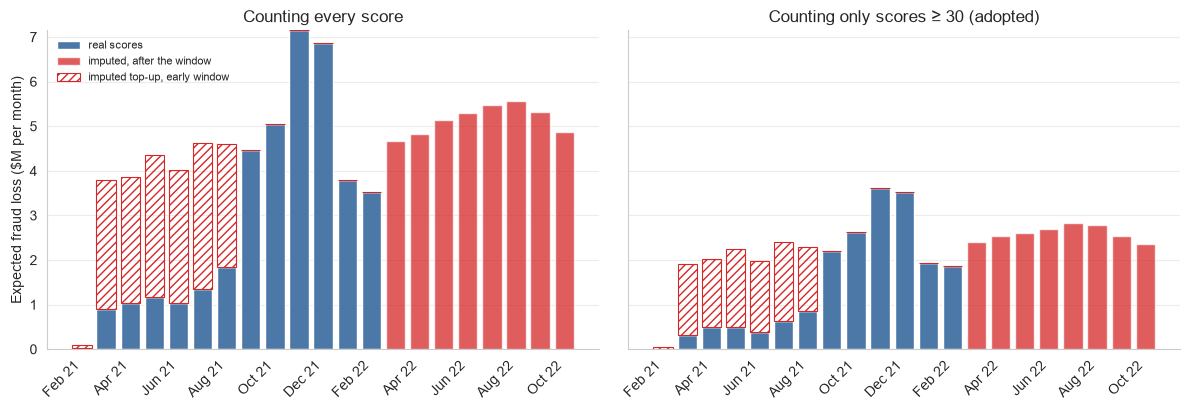

In [5]:
monthly = daily.resample("MS").sum()
early = monthly.index < pd.Timestamp("2021-09-01")
after = monthly.index >= pd.Timestamp("2022-03-01")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, m, title in [(axes[0], 0, "Counting every score"), (axes[1], 30, "Counting only scores ≥ 30 (adopted)")]:
    observed = monthly[f"observed_loss_min{m}"] / 1e6
    imputed = monthly[f"imputed_loss_min{m}"] / 1e6
    added_after = imputed.where(after, 0.0)
    # February 2022 holds one day after the window (the 28th), so top it up to the imputed level as well.
    top_up_early = (imputed - observed).clip(lower=0).where(early, 0.0)
    x = np.arange(len(monthly))
    ax.bar(x, observed, color=OBS_BLUE, width=0.8, label="real scores")
    ax.bar(x, added_after, bottom=observed, color=IMP_RED, alpha=0.75, width=0.8, label="imputed, after the window")
    ax.bar(x, top_up_early, bottom=observed, facecolor="none", edgecolor=IMP_RED, hatch="////", linewidth=0.8,
           width=0.8, label="imputed top-up, early window")
    ax.set_xticks(x[::2], [d.strftime("%b %y") for d in monthly.index[::2]], rotation=45, ha="right")
    ax.set(title=title, xlabel="")
    ax.grid(axis="x", visible=False)
    sns.despine(ax=ax)
    print(f"MIN_SCORE {m:>2}: real ${observed.sum():.1f}M | imputed after the window ${added_after.sum():.1f}M | "
          f"early top-up ${top_up_early.sum():.1f}M")
axes[0].set_ylabel("Expected fraud loss ($M per month)")
axes[0].legend(frameon=False, fontsize=8, loc="upper left")
fig.tight_layout()
plt.show()

## 6. Real scores are per day; imputed values are band averages

A real score is specific to one user-day and can be anywhere from 8 to 99. An imputed value is the average for a spend band, so every day in a band gets the same number and extremes disappear. The comparison below uses user-days that spent \$2,000 or more.

/Users/matthewlinfred/MAST30034_Python/project2/.proj2_bnpl/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


/Users/matthewlinfred/MAST30034_Python/project2/.proj2_bnpl/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


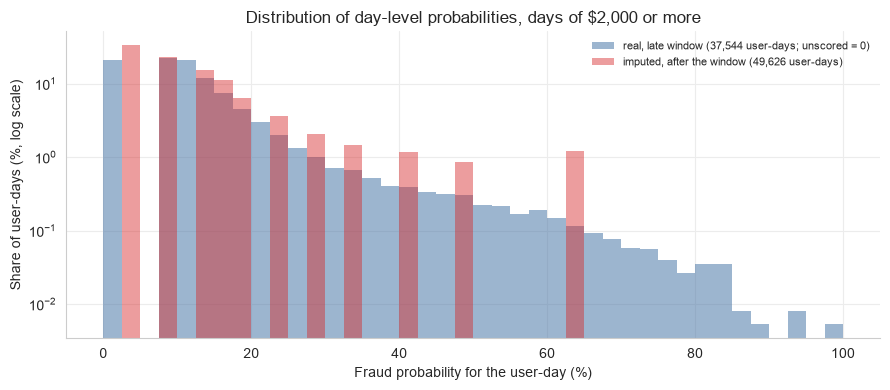

mean probability: real 0.121, imputed 0.122
largest value   : real 0.99, imputed 0.65


In [6]:
MIN_SPEND = 2000
real = (late_days.where((F.col("day_spend") >= MIN_SPEND))
        .select((F.coalesce("consumer_score", F.lit(0.0)) / 100).alias("p")).toPandas()["p"])
imputed_p = (user_days.where((F.col("order_date") > END) & (F.col("day_spend") >= MIN_SPEND))
             .join(F.broadcast(lookup.select("spend_bin", "p_day_min0")), "spend_bin", "left")
             .select(F.coalesce("p_day_min0", F.lit(0.0)).alias("p")).toPandas()["p"])

bins = np.arange(0, 1.0001, 0.025)
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(x=real * 100, bins=bins * 100, stat="percent", color=OBS_BLUE, alpha=0.55, edgecolor="none",
             label=f"real, late window ({len(real):,} user-days; unscored = 0)", ax=ax)
sns.histplot(x=imputed_p * 100, bins=bins * 100, stat="percent", color=IMP_RED, alpha=0.45, edgecolor="none",
             label=f"imputed, after the window ({len(imputed_p):,} user-days)", ax=ax)
ax.set_yscale("log")
ax.set(xlabel="Fraud probability for the user-day (%)", ylabel="Share of user-days (%, log scale)",
       title=f"Distribution of day-level probabilities, days of ${MIN_SPEND:,} or more")
ax.legend(frameon=False, fontsize=8)
sns.despine(ax=ax)
fig.tight_layout()
plt.show()
print(f"mean probability: real {real.mean():.3f}, imputed {imputed_p.mean():.3f}")
print(f"largest value   : real {real.max():.2f}, imputed {imputed_p.max():.2f}")

## 7. The imputation with a cutoff of 50

From here on, a score only counts as a fraud signal if it is **50 or above**, the `flagged` tier in `fraud_penalty.ipynb`. A cutoff of 30 treats a 30–50% score as a likely loss, which is hard on merchants given how sharply the scores rise at the regime change. Above 50, fraud is more likely than not.

The lookup is the same one as before with the higher cutoff: per spend band, the spend-weighted average of the scores of 50 and above, with every other day counted as 0.

Spend bands with a non-zero imputed probability at a cutoff of 50:


<>:13: SyntaxWarning: invalid escape sequence '\$'
<>:13: SyntaxWarning: invalid escape sequence '\$'
/var/folders/kv/bykr7sfs0439lgz122sd6d580000gn/T/ipykernel_46237/2739077085.py:13: SyntaxWarning: invalid escape sequence '\$'
  ax.set(ylabel="Expected loss per \$100 transacted (dollars)",


,spend_from,days,p_day_min30,p_day_min50
27,12592.6826,432,0.3973,0.0215
67,15855.6198,318,0.4779,0.1944
15,19999.5093,485,0.6450,0.6098


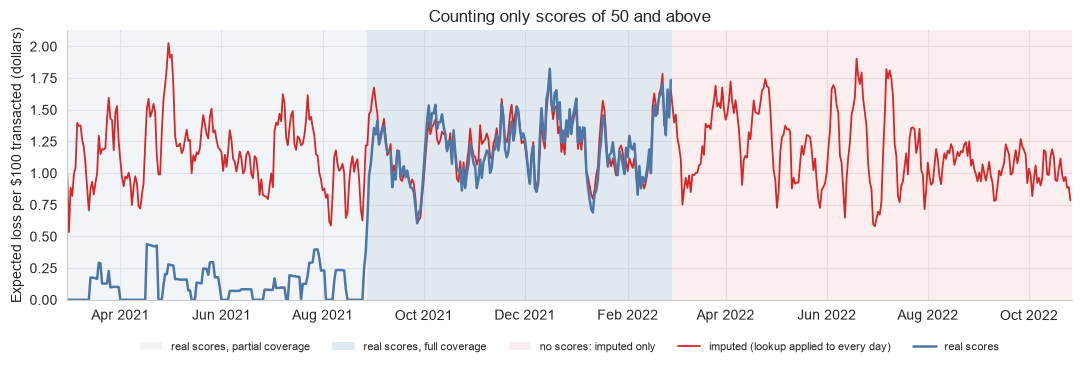

In [7]:
CUTOFF = 50

bands = lookup_late[lookup_late[f"p_day_min{CUTOFF}"] > 0]
print(f"Spend bands with a non-zero imputed probability at a cutoff of {CUTOFF}:")
display(bands[["spend_from", "days", "p_day_min30", f"p_day_min{CUTOFF}"]].round(4))

observed = (rolling[f"observed_loss_min{CUTOFF}"] / rolling["value"] * 100).where(in_window)
imputed = rolling[f"imputed_loss_min{CUTOFF}"] / rolling["value"] * 100
fig, ax = plt.subplots(figsize=(11, 3.8))
shade_periods(ax)
ax.plot(imputed.index, imputed, color=IMP_RED, linewidth=1.3, label="imputed (lookup applied to every day)")
ax.plot(observed.index, observed, color=OBS_BLUE, linewidth=1.8, label="real scores")
ax.set(ylabel="Expected loss per \$100 transacted (dollars)",
       title=f"Counting only scores of {CUTOFF} and above")
ax.set_ylim(0, None)
ax.legend(frameon=False, fontsize=8, ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.12))
sns.despine(ax=ax)
fig.tight_layout()
plt.show()

## 8. The top 100 under the imputation

Each transaction gets a consumer fraud probability from one of two sources:

- **Late window (28 Aug 2021 – 27 Feb 2022):** the real score for that user-day.
- **Everywhere else (early window and after the window):** the red line, i.e. the lookup value for that user-day's spend band.

This is Test B in `fraud_penalty.ipynb`. The rest follows that notebook: the day's probability is split across the day's transactions by dollar value, combined with the merchant's own score for that day (real scores only, not imputed), and expected loss is the combined probability × the transaction's value, with the full principal lost. The loss comes off `estimated_bnpl_revenue` and the v2 score is recomputed with the revenue term swapped.

In [8]:
K, REVENUE_WEIGHT = 300, 0.70   # from merchant_ranking_v2.ipynb

merchant_scores = (spark.read.parquet(str(PROCESSED_PATH / "merchant_fraud_probability"))
                   .select("merchant_abn", F.to_date("order_datetime").alias("order_date"),
                           F.col("fraud_probability").alias("merchant_score")))
txn = (
    spark.read.parquet(str(PROCESSED_PATH / "transactions_clean"))
    .withColumn("order_date", F.to_date("order_datetime"))
    .join(user_days, ["user_id", "order_date"])
    .join(F.broadcast(lookup.select("spend_bin", *[f"p_day_min{m}" for m in MIN_SCORES])), "spend_bin", "left")
    .join(F.broadcast(merchant_scores), ["merchant_abn", "order_date"], "left")
)

full_coverage = F.col("order_date").between(REGIME_START, END)
loss_aggs = []
for m in MIN_SCORES:
    p_day = F.when(full_coverage, p_if_at_least("consumer_score", m)) \
             .otherwise(F.coalesce(F.col(f"p_day_min{m}"), F.lit(0.0)))
    p_consumer = p_day * F.col("dollar_value") / F.col("day_spend")
    p_fraud = 1 - (1 - p_consumer) * (1 - p_if_at_least("merchant_score", m))
    loss_aggs += [F.sum(p_fraud * F.col("dollar_value")).alias(f"loss_min{m}"),
                  F.sum(F.when(~full_coverage, p_consumer * F.col("dollar_value")).otherwise(0.0))
                   .alias(f"imputed_loss_min{m}")]
merchant_loss = txn.groupBy("merchant_abn").agg(*loss_aggs).toPandas()

ranking = pd.read_parquet(PROCESSED_PATH / "merchant_ranking_v2.parquet")
losses = ranking[["merchant_abn"]].merge(merchant_loss, on="merchant_abn", how="left").fillna(0.0)


def revenue_term(values, n):
    shrinkage = n / (n + K)
    return shrinkage * values.rank(pct=True) * 100 + (1 - shrinkage) * 50


def rank_with_loss(expected_loss):
    # v2's score with the revenue term rebuilt from revenue net of `expected_loss`.
    t = ranking.copy()
    t["expected_fraud_loss"] = expected_loss
    t["fraud_adjusted_revenue"] = t["estimated_bnpl_revenue"] - t["expected_fraud_loss"]
    t["loss_to_revenue"] = t["expected_fraud_loss"] / t["estimated_bnpl_revenue"]
    old_term = revenue_term(t["estimated_bnpl_revenue"], t["transaction_count"])
    new_term = revenue_term(t["fraud_adjusted_revenue"], t["transaction_count"])
    t["score_imputed"] = t["score"] - REVENUE_WEIGHT * old_term + REVENUE_WEIGHT * new_term
    t["rank_imputed"] = t["score_imputed"].rank(ascending=False, method="first").astype(int)
    t["rank_change"] = t["rank_overall"] - t["rank_imputed"]
    return t


# With no loss, the swap must reproduce v2 exactly.
assert np.allclose(rank_with_loss(0.0)["score_imputed"], ranking["score"])

top_v2 = set(ranking.nsmallest(100, "rank_overall")["merchant_abn"])
rows = []
for m in MIN_SCORES:
    t = rank_with_loss(losses[f"loss_min{m}"])
    top = t.nsmallest(100, "rank_imputed")
    rows.append({"cutoff": m, "expected loss ($M)": t["expected_fraud_loss"].sum() / 1e6,
                 "of which imputed ($M)": losses[f"imputed_loss_min{m}"].sum() / 1e6,
                 "share of BNPL revenue": t["expected_fraud_loss"].sum() / t["estimated_bnpl_revenue"].sum(),
                 "merchants with a loss": int((t["expected_fraud_loss"] > 0).sum()),
                 "loss > revenue": int((t["fraud_adjusted_revenue"] < 0).sum()),
                 "Spearman vs v2": spearmanr(t["rank_overall"], t["rank_imputed"]).statistic,
                 "top-100 overlap with v2": len(top_v2 & set(top["merchant_abn"])),
                 "top-100 expected loss ($K)": top["expected_fraud_loss"].sum() / 1e3})
pd.DataFrame(rows).set_index("cutoff").round(3)

/Users/matthewlinfred/MAST30034_Python/project2/.proj2_bnpl/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


,expected loss ($M),of which imputed ($M),share of BNPL revenue,merchants with a loss,loss > revenue,Spearman vs v2,top-100 overlap with v2,top-100 expected loss ($K)
cutoff,,,,,,,,
0,68.762,46.245,0.714,3970,747,0.820,95,1559.670
30,34.050,22.784,0.353,2480,226,0.976,100,282.078
50,18.901,12.756,0.196,1183,152,0.985,99,19.314


In [9]:
r_c = rank_with_loss(losses[f"loss_min{CUTOFF}"])
top_c = set(r_c.nsmallest(100, "rank_imputed")["merchant_abn"])
v2_top100 = r_c[r_c["rank_overall"] <= 100]

COLS = ["name", "rank_overall", "rank_imputed", "rank_change", "estimated_bnpl_revenue",
        "expected_fraud_loss", "loss_to_revenue", "avg_transaction_value"]
print(f"Cutoff {CUTOFF}: {len(top_v2 & top_c)} of the v2 top 100 stay in the top 100; "
      f"{(v2_top100['rank_change'] != 0).sum()} change position, by at most "
      f"{v2_top100['rank_change'].abs().max()} places")
print("\nLeft the top 100:")
display(r_c[r_c["merchant_abn"].isin(top_v2 - top_c)].sort_values("rank_overall")[COLS].round(4))
print("Entered the top 100:")
display(r_c[r_c["merchant_abn"].isin(top_c - top_v2)].sort_values("rank_imputed")[COLS].round(4))
print("v2 top 100, largest expected loss relative to revenue:")
display(v2_top100.nlargest(5, "loss_to_revenue")[COLS].round(4))
print("Largest falls among the v2 top 500:")
r_c[r_c["rank_overall"] <= 500].nsmallest(8, "rank_change")[COLS].round(4)

Cutoff 50: 99 of the v2 top 100 stay in the top 100; 38 change position, by at most 5 places

Left the top 100:


,name,rank_overall,rank_imputed,rank_change,estimated_bnpl_revenue,expected_fraud_loss,loss_to_revenue,avg_transaction_value
97,Rutrum Magna Cras LLC,98,101,-3,281596.9528,5.3772,0.0,486.9085


Entered the top 100:


,name,rank_overall,rank_imputed,rank_change,estimated_bnpl_revenue,expected_fraud_loss,loss_to_revenue,avg_transaction_value
100,Id Erat Etiam Consulting,101,100,1,100271.5485,0.1893,0.0,88.7879


v2 top 100, largest expected loss relative to revenue:


,name,rank_overall,rank_imputed,rank_change,estimated_bnpl_revenue,expected_fraud_loss,loss_to_revenue,avg_transaction_value
73,Semper Auctor PC,74,79,-5,378725.1112,17694.7603,0.0467,2198.0257
89,Nec Incorporated,90,91,-1,541305.2503,577.2214,0.0011,1878.1529
69,Tempus Non Lacinia Corporation,70,71,-1,395634.6492,116.5698,0.0003,1352.9116
71,Tellus Aenean Corporation,72,74,-2,410180.1862,108.6259,0.0003,1011.7002
50,Ac Ipsum LLC,51,54,-3,425858.9161,82.1618,0.0002,1127.1312


Largest falls among the v2 top 500:


,name,rank_overall,rank_imputed,rank_change,estimated_bnpl_revenue,expected_fraud_loss,loss_to_revenue,avg_transaction_value
302,Lacus Aliquam Corporation,303,4026,-3723,406414.8155,1.201593e+06,2.9566,6306.9305
494,Commodo Ipsum Industries,495,4025,-3530,402545.4697,1.441408e+06,3.5807,9909.2506
435,Lacus Mauris Limited,436,448,-12,87985.5261,2.612974e+02,0.0030,1542.2745
429,Viverra Donec LLC,430,441,-11,83784.0133,6.708710e+01,0.0008,1017.2568
447,Vitae Velit Institute,448,458,-10,60530.1587,1.897000e-01,0.0000,763.4802
273,Euismod In LLC,274,283,-9,189783.9840,0.000000e+00,0.0000,1493.8210
374,Lorem Eu Corp.,375,384,-9,86987.1482,3.816900e+00,0.0000,678.7164
379,Parturient Incorporated,380,389,-9,148595.7197,0.000000e+00,0.0000,2185.6233


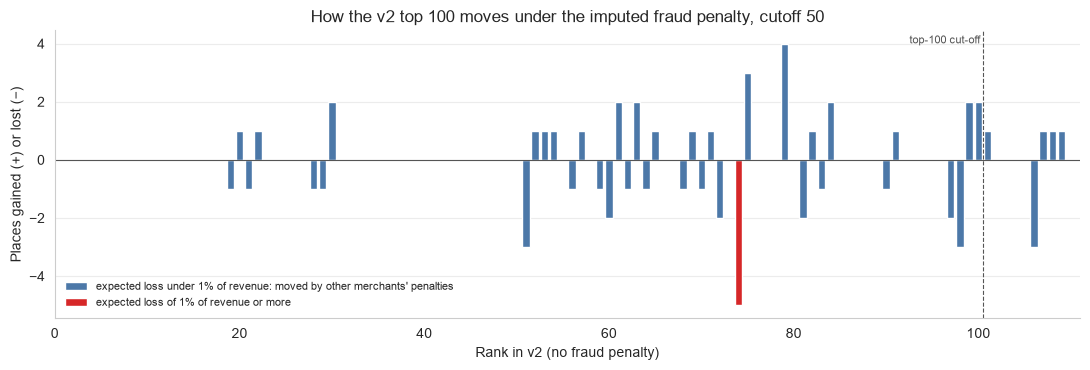

In [10]:
OWN_LOSS = 0.01   # expected loss of at least 1% of the merchant's BNPL revenue
shown = r_c[r_c["rank_overall"] <= 110].sort_values("rank_overall")
own_loss = shown["loss_to_revenue"] >= OWN_LOSS

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.bar(shown.loc[~own_loss, "rank_overall"], shown.loc[~own_loss, "rank_change"], color=OBS_BLUE, width=0.8,
       label="expected loss under 1% of revenue: moved by other merchants' penalties")
ax.bar(shown.loc[own_loss, "rank_overall"], shown.loc[own_loss, "rank_change"], color=IMP_RED, width=0.8,
       label="expected loss of 1% of revenue or more")
ax.axhline(0, color="#555555", linewidth=0.8)
ax.axvline(100.5, color="#555555", linewidth=0.8, linestyle="--")
ax.text(100.2, ax.get_ylim()[1] * 0.9, "top-100 cut-off", ha="right", fontsize=8, color="#555555")
ax.set(xlabel="Rank in v2 (no fraud penalty)", ylabel="Places gained (+) or lost (−)",
       title=f"How the v2 top 100 moves under the imputed fraud penalty, cutoff {CUTOFF}", xlim=(0, 111))
ax.grid(axis="x", visible=False)
ax.legend(frameon=False, fontsize=8, loc="lower left")
sns.despine(ax=ax)
fig.tight_layout()
plt.show()

## 9. The raw scores either side of the break

Imputing the early window from the late-window lookup rests on one claim: the early scores are low because of how they were recorded, not because there was less fraud. This section looks at the supplied scores themselves, with nothing imputed.

Every dot below is one supplied score. The dashed line is 28 Aug 2021, the first day of the second transaction snapshot.

/Users/matthewlinfred/MAST30034_Python/project2/.proj2_bnpl/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/Users/matthewlinfred/MAST30034_Python/project2/.proj2_bnpl/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/Users/matthewlinfred/MAST30034_Python/project2/.proj2_bnpl/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


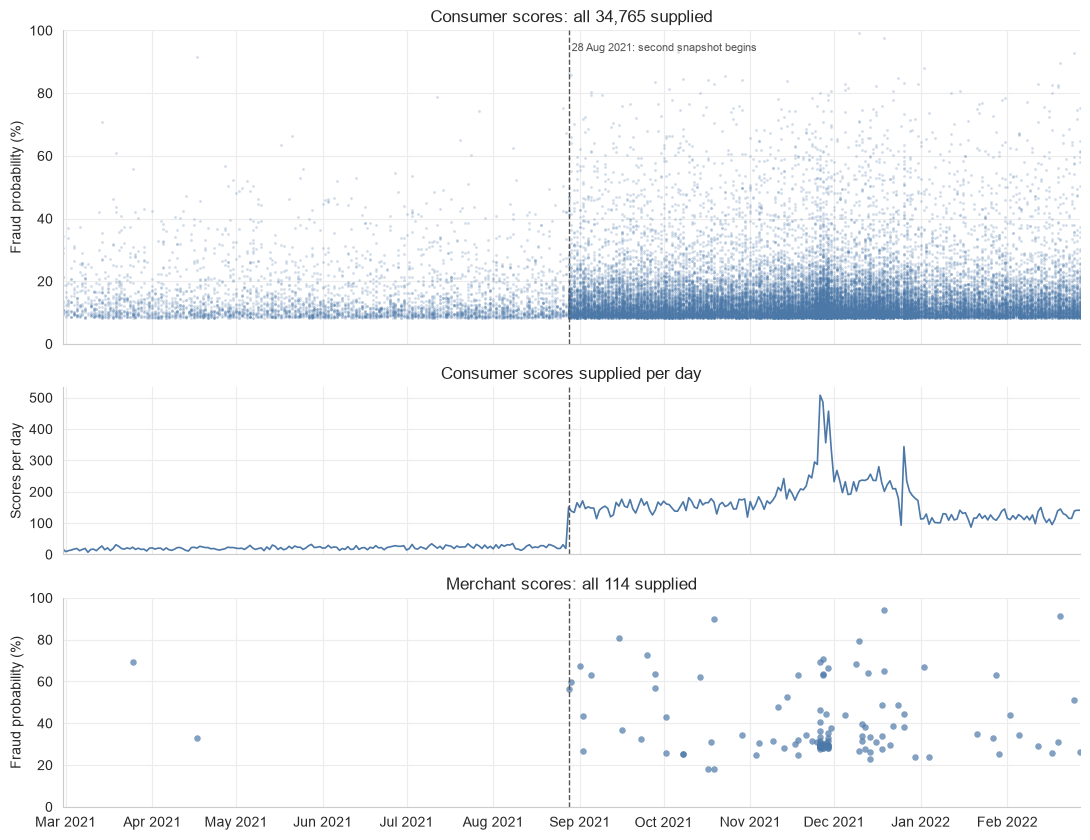

Merchant scores: 2 before the break, 112 from it onwards


,value transacted per day ($M),"user-days of $3,000+ per day",consumer scores per day
4 weeks before the break,3.69,84.93,24.68
4 weeks after the break,3.75,88.64,149.86


In [11]:
BREAK = pd.Timestamp(REGIME_START)
EARLY_ORANGE = "#F58518"      # early-window scores; late-window scores stay blue

consumer_raw = consumer_scores.toPandas()
merchant_raw = merchant_scores.toPandas()
for frame in (consumer_raw, merchant_raw):
    frame["order_date"] = pd.to_datetime(frame["order_date"])

# Every user-day of $1,300 or more in the scoring window (no day below that is ever scored),
# with the number of purchases the user made that day.
large_days = (
    spark.read.parquet(str(PROCESSED_PATH / "transactions_clean"))
    .withColumn("order_date", F.to_date("order_datetime"))
    .where(F.col("order_date").between(START, END))
    .groupBy("user_id", "order_date")
    .agg(F.sum("dollar_value").alias("day_spend"), F.count("*").alias("purchases"))
    .where(F.col("day_spend") >= 1300)
    .join(consumer_scores, ["user_id", "order_date"], "left")
    .toPandas()
)
large_days["order_date"] = pd.to_datetime(large_days["order_date"])
large_days["period"] = np.where(large_days["order_date"] < BREAK, "early", "late")
large_days["scored"] = large_days["consumer_score"].notna()
assert large_days["scored"].sum() == len(consumer_raw), "every supplied score should be on a day of $1,300 or more"

per_day = consumer_raw.groupby("order_date").size().reindex(
    pd.date_range(START, END), fill_value=0)
fig, axes = plt.subplots(3, 1, figsize=(11, 8.5), sharex=True, height_ratios=[3, 1.6, 2])
axes[0].scatter(consumer_raw["order_date"], consumer_raw["consumer_score"], s=4, color=OBS_BLUE,
                alpha=0.25, linewidths=0)
axes[0].set(ylabel="Fraud probability (%)", ylim=(0, 100),
            title=f"Consumer scores: all {len(consumer_raw):,} supplied")
axes[1].plot(per_day.index, per_day.values, color=OBS_BLUE, linewidth=1.2)
axes[1].set(ylabel="Scores per day", title="Consumer scores supplied per day")
axes[1].set_ylim(0, None)
axes[2].scatter(merchant_raw["order_date"], merchant_raw["merchant_score"], s=22, color=OBS_BLUE,
                alpha=0.7, linewidths=0)
axes[2].set(ylabel="Fraud probability (%)", ylim=(0, 100),
            title=f"Merchant scores: all {len(merchant_raw)} supplied")
for ax in axes:
    ax.axvline(BREAK, color="#555555", linewidth=1, linestyle="--")
    ax.set_xlim(pd.Timestamp(START), pd.Timestamp(END))
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
    sns.despine(ax=ax)
axes[0].text(BREAK, 96, " 28 Aug 2021: second snapshot begins", fontsize=8, color="#555555", va="top")
fig.tight_layout()
plt.show()

# Four weeks either side of the break: did spending change, or only the scoring?
near = large_days[(large_days["order_date"] >= BREAK - pd.Timedelta(days=28))
                  & (large_days["order_date"] < BREAK + pd.Timedelta(days=28))]
big = near[near["day_spend"] >= 3000]
value = daily["value"].groupby(np.where(daily.index < BREAK, "early", "late")).apply(
    lambda s: s[(s.index >= BREAK - pd.Timedelta(days=28)) & (s.index < BREAK + pd.Timedelta(days=28))].mean())
print(f"Merchant scores: {(merchant_raw['order_date'] < BREAK).sum()} before the break, "
      f"{(merchant_raw['order_date'] >= BREAK).sum()} from it onwards")
pd.DataFrame({
    "value transacted per day ($M)": value / 1e6,
    "user-days of $3,000+ per day": big.groupby("period").size() / 28,
    "consumer scores per day": near.groupby("period")["scored"].sum() / 28,
}).rename(index={"early": "4 weeks before the break", "late": "4 weeks after the break"}).round(2)

Spending carries straight through the break; the number of scores per day does not. Two checks on what changed: which days get a score at all, and what score they get for a given spend.

User-days of $3,000 or more, by number of purchases that day:


user-days                       share scored                \
purchases            1     2     3 4 or more            1      2      3   
period                                                                    
early window      5510  5102  2370      1044        0.000  0.456  0.451   
late window       5633  6192  3690      2478        0.986  0.989  0.988   

                        
purchases    4 or more  
period                  
early window     0.445  
late window      0.992

Gap to the late-window relationship, in percentage points:


,mean,standard deviation
"late scores − late curve, at the day's spend",0.01,2.19
"early scores − late curve, at the day's spend",-10.98,5.24
"early scores − late curve, at half the day's spend",0.03,2.07


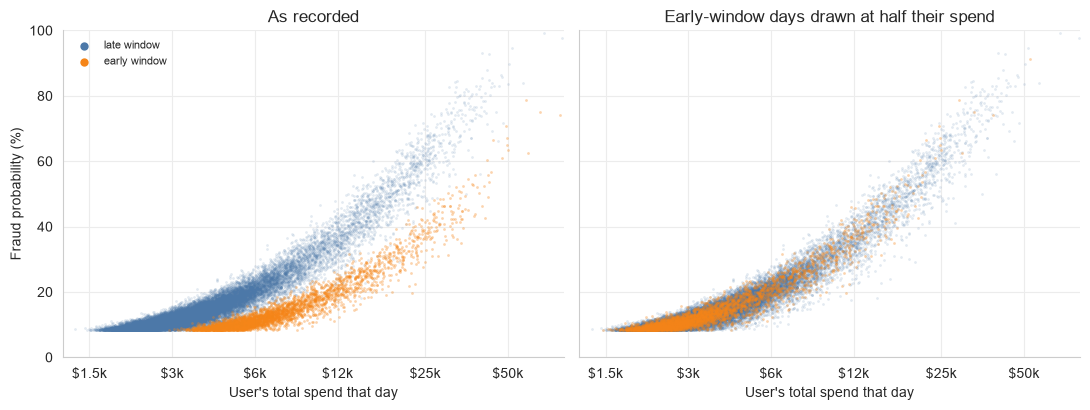

In [12]:
# 1. Which days get a score: by number of purchases the user made that day (days of $3,000 or more).
eligible = large_days[large_days["day_spend"] >= 3000].assign(
    purchases=lambda d: d["purchases"].clip(upper=4).map({1: "1", 2: "2", 3: "3", 4: "4 or more"}))
share = eligible.pivot_table(index="period", columns="purchases", values="scored", aggfunc=["size", "mean"])
share = share.rename(columns={"size": "user-days", "mean": "share scored"},
                     index={"early": "early window", "late": "late window"})
print("User-days of $3,000 or more, by number of purchases that day:")
display(share.round(3))

# 2. What score a day gets for its spend. The late-window relationship is summarised as the
#    median score per band of spend, then the early scores are compared against it.
scored = large_days[large_days["scored"]]
late_scored, early_scored = scored[scored["period"] == "late"], scored[scored["period"] == "early"]
edges = np.linspace(np.log(1300), np.log(60_000), 60)
late_curve = late_scored.groupby(pd.cut(np.log(late_scored["day_spend"]), edges), observed=True)["consumer_score"].median()
curve_x = np.array([band.mid for band in late_curve.index])


def late_score_at(spend):
    return np.interp(np.log(spend), curve_x, late_curve.to_numpy())


gaps = {"late scores − late curve, at the day's spend": late_scored["consumer_score"] - late_score_at(late_scored["day_spend"]),
        "early scores − late curve, at the day's spend": early_scored["consumer_score"] - late_score_at(early_scored["day_spend"]),
        "early scores − late curve, at half the day's spend": early_scored["consumer_score"] - late_score_at(early_scored["day_spend"] / 2)}
print("Gap to the late-window relationship, in percentage points:")
display(pd.DataFrame({name: {"mean": gap.mean(), "standard deviation": gap.std()} for name, gap in gaps.items()}).T.round(2))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, divisor, title in [(axes[0], 1, "As recorded"), (axes[1], 2, "Early-window days drawn at half their spend")]:
    ax.scatter(late_scored["day_spend"], late_scored["consumer_score"], s=4, color=OBS_BLUE, alpha=0.15,
               linewidths=0, label="late window")
    ax.scatter(early_scored["day_spend"] / divisor, early_scored["consumer_score"], s=4, color=EARLY_ORANGE,
               alpha=0.35, linewidths=0, label="early window")
    ax.set_xscale("log")
    ax.set_xticks([1500, 3000, 6000, 12000, 25000, 50000], ["$1.5k", "$3k", "$6k", "$12k", "$25k", "$50k"])
    ax.minorticks_off()
    ax.set(xlabel="User's total spend that day", title=title, xlim=(1200, 80_000), ylim=(0, 100))
    sns.despine(ax=ax)
axes[0].set_ylabel("Fraud probability (%)")
legend = axes[0].legend(frameon=False, fontsize=8, markerscale=3)
for handle in legend.legend_handles:
    handle.set_alpha(1)
fig.tight_layout()
plt.show()

### What the raw scores show

The early window is not a thinner sample of the same scores. It follows a different rule, and the rule changes on the day the snapshot changes.

- **Single-purchase days are never scored in the early window.** Of 5,510 user-days of \$3,000 or more with one purchase, one has a score. In the late window 99% do. Size does not matter: a single \$50,000 purchase goes unscored before 28 Aug 2021.
- **Multi-purchase days are scored as if the user had spent half as much.** Drawn at half their spend, the early scores sit on the late-window relationship with no gap (0.0 points) and the same scatter (2.1 points against 2.2). At their actual spend they sit 11 points below it. Halving also explains why only about 45% of multi-purchase days of \$3,000 or more are scored: the spend needed to get a score doubles.
- **Nothing else changes at the break.** Value transacted and the number of large days are level across it (\$3.69M and \$3.75M a day; 85 and 89 large days a day), while consumer scores go from 25 to 150 a day. Merchant scores go from 2 in six months to 112 in the next six.
- **It is not our cleaning.** For every early-window user-day of \$3,000 or more, spend and purchase count in `transactions_clean` equal those in the raw snapshot.

**What this does and does not establish.** A change this exact, on a file boundary, with spending unchanged, is a change in how the scores were produced, not in how much fraud there was. So the two halves of the window are on different scales and should not be averaged together, which is what the un-imputed loss rate in `fraud_penalty.ipynb` Part B does. It does not show which of the two rules is the correct one. Treating the late-window rule as the true level is an assumption: it is the rule with complete coverage and the one in force when the scores end, and it gives the higher, more cautious loss figure.

## Reading the plots

- **§3.** In the late window a user-day is almost never scored below about \$1,500, about half are scored at \$2,000, and every day above about \$3,000 is. In the early window the same curve tops out near 60%, and the probabilities are roughly a third as large. The imputation uses the late-window curve.
- **§4.** Where real scores have full coverage (darker blue band), the imputed line sits on top of the real one, including its week-to-week movement. That is the evidence that daily spend is enough to reproduce the scores in aggregate. In the early window the real line drops to about a quarter of the imputed one on the same day the data snapshot changes, with no matching change in spending. After the window, the imputed line carries on at the late-window level, because spending patterns carry on.
- **§5.** The imputation adds roughly as much loss after the window as the real scores record inside it, and re-pricing the early months adds about half as much again. These totals cover every merchant in the transactions, including the 396 with no metadata, so they are higher than the ranked-merchant totals in `fraud_penalty.ipynb`.
- **§6.** Imputed values are band averages: they match the real scores on average (mean 0.12 for both) but come in a handful of fixed levels and never exceed 0.65, where real scores reach 0.99. So the imputation is sound for totals and for a merchant's overall exposure, and should not be read as a statement about any single transaction.
- **§7.** With a cutoff of 50, only user-days of about \$12,600 or more get a non-zero imputed probability (2%, 19% and 61% across the three top bands). In the late window the red line follows the real one week by week; the totals agree by construction, since the lookup is fitted there (the held-out check in `fraud_penalty.ipynb` §11 gives 95% of observed loss at this cutoff). In the early window the real scores give about a sixth of the imputed level.
- **§8, totals.** Expected fraud loss is \$18.9M, 20% of the \$96.4M of estimated BNPL revenue, of which \$12.8M is imputed. A cutoff of 30 gives \$34.1M (35%). The number of merchants whose loss exceeds their revenue falls from 226 to 152.
- **§8, top 100.** 99 of the v2 top 100 stay. Ranks 100 and 101 swap (Malesuada Vel Associates out, Id Erat Etiam Consulting in), and neither has an expected loss above \$1. 43 of the top 100 change position, by at most 5 places. Almost all of that is knock-on movement: the revenue term is a percentile rank, so penalties on merchants elsewhere shift everyone's percentile slightly. Only Semper Auctor PC carries a loss of its own (\$17.7K, 4.7% of its revenue; rank 68 to 72). The top 100's combined expected loss is \$19K, against \$282K at a cutoff of 30.
- **§8, further down.** The penalty lands on big-ticket merchants outside the shortlist. The largest fall is Lacus Aliquam Corporation, from 307 to 4,025, with an expected loss of about three times its revenue.
- **The cutoff does not decide the shortlist.** The top 100 has the same 99 merchants at a cutoff of 30 and of 50. The choice changes the estimated cost of fraud and how hard big-ticket merchants further down are penalised.
- **§9.** The supplied scores change rule on 28 Aug 2021 while spending does not. Before that date single-purchase days are never scored and other days are scored as if they were half their size; after it every large day is scored at its full size. This is the case for re-pricing the early window from the late-window lookup. It shows the early scores are understated relative to the late ones, not which of the two is right.

**What the plots cannot show.** Whether scoring after February 2022 really followed the late-window pattern. The imputation assumes it did; the one regime change visible in §4 is a reminder that it might not have.